Dataset exploration


# Machine Learning Final Project  
## From Hidden Structure to Prediction: Breast Cancer Wisconsin Dataset

This project studies the Breast Cancer Wisconsin Diagnostic dataset. The dataset contains numerical measurements extracted from cell nuclei images.  

The goal is to investigate the dataset from two perspectives:

1. **Unsupervised learning:** Can we discover hidden structure, low-dimensional patterns, or natural groups in the data?
2. **Supervised learning:** Can we predict whether a tumor is malignant or benign?

The supervised target is the tumor diagnosis. The unsupervised goal is to study whether dimensionality reduction and clustering methods reveal meaningful structure related to the diagnosis.

In [ ]:
# Basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_breast_cancer

# Preprocessing and splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Display settings
pd.set_option("display.max_columns", None)

# Reproducibility
RANDOM_STATE = 42

Loading the dataset

In [ ]:
# Load Breast Cancer Wisconsin dataset
data = load_breast_cancer()

# Create feature DataFrame
X = pd.DataFrame(data.data, columns=data.feature_names)

# Original sklearn target:
# 0 = malignant
# 1 = benign
y_original = pd.Series(data.target, name="original_target")

# For our project, we define:
# malignant = 1
# benign = 0
# This is useful because malignant is the medically critical class (Easier to interpret with F1 score and other effectiveness parameters).
y = y_original.map({0: 1, 1: 0})
y.name = "diagnosis"

# We create df only for initial exploratory data analysis.
# It combines features and labels so that we can make plots grouped by diagnosis.
# IMPORTANT: df will NOT be used for model training.
df = X.copy()
df["diagnosis"] = y
df["diagnosis_label"] = df["diagnosis"].map({1: "malignant", 0: "benign"})

In [ ]:
# Dataset dimensions
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nNumber of samples:", X.shape[0])
print("Number of features:", X.shape[1])

Feature matrix shape: (569, 30)
Target vector shape: (569,)

Number of samples: 569
Number of features: 30


In [ ]:
# Display first rows of the feature matrix
display(X.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Df structure

In [ ]:
# Display first rows of the dataframe
display(df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,diagnosis_label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1,malignant


In [ ]:
# Dataset dimensions
print("Dataset shape:", df.shape)
print("Number of samples:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (569, 32)
Number of samples: 569
Number of columns: 32


In [ ]:
# General information about the dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
# Count the different data types
display(df.dtypes.value_counts())

,count
float64,30
int64,1
object,1


In [ ]:
# Define target column
target_col = "diagnosis"

# Separate features and target
X = df.drop(columns=[target_col, "diagnosis_label"], errors="ignore")
y = df[target_col]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

Feature matrix shape: (569, 30)
Target vector shape: (569,)


In [ ]:
# Missing values in the full dataframe
missing_values = df.isna().sum()

display(missing_values[missing_values > 0])

print("Total missing values:", df.isna().sum().sum())

,0


Total missing values: 0


In [ ]:
# Check full duplicated rows
duplicate_rows = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_rows)

Number of duplicated rows: 0


In [ ]:
# Check duplicated feature rows
duplicate_feature_rows = X.duplicated().sum()

print("Number of duplicated feature rows:", duplicate_feature_rows)

Number of duplicated feature rows: 0


In [ ]:
# Since no problematic missing values or duplicates were found,
# we keep the current feature matrix and target vector.

X_clean = X.copy()
y_clean = y.copy()

print("Clean feature matrix shape:", X_clean.shape)
print("Clean target vector shape:", y_clean.shape)

Clean feature matrix shape: (569, 30)
Clean target vector shape: (569,)


After checking the shape, data types, missing values, duplicated rows, and conflicting duplicates, no problematic observations were found. Therefore, the cleaned dataset is the same as the original dataset.

In [ ]:
# Summary statistics for the numerical features
display(X_clean.describe())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Time to Split the Data (80/20)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_clean
)

print("Training feature matrix shape:", X_train.shape)
print("Test feature matrix shape:", X_test.shape)
print("Training target vector shape:", y_train.shape)
print("Test target vector shape:", y_test.shape)

Training feature matrix shape: (455, 30)
Test feature matrix shape: (114, 30)
Training target vector shape: (455,)
Test target vector shape: (114,)


Did the stratification work?

In [ ]:
print("Original target distribution:")
display(y_clean.value_counts(normalize=True))

print("Training target distribution:")
display(y_train.value_counts(normalize=True))

print("Test target distribution:")
display(y_test.value_counts(normalize=True))

Original target distribution:


,proportion
diagnosis,
0,0.627417
1,0.372583


Training target distribution:


,proportion
diagnosis,
0,0.626374
1,0.373626


Test target distribution:


,proportion
diagnosis,
0,0.631579
1,0.368421


Pre processing

In [ ]:
# Create a training dataframe for detailed EDA after the split.
# This keeps the test set untouched for final evaluation.

train_df = X_train.copy()
train_df["diagnosis"] = y_train
train_df["diagnosis_label"] = train_df["diagnosis"].map({
    1: "malignant",
    0: "benign"
})

display(train_df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,diagnosis_label
10,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,0.3795,1.1870,2.466,40.51,0.004029,0.009269,0.01101,0.007591,0.01460,0.003042,19.19,33.88,123.80,1150.0,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452,1,malignant
170,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,0.2360,0.6656,1.670,17.43,0.008045,0.011800,0.01683,0.012410,0.01924,0.002248,13.50,15.64,86.97,549.1,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771,0,benign
407,12.85,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,0.4993,1.7980,2.552,41.24,0.006011,0.044800,0.05175,0.013410,0.02669,0.007731,14.40,27.01,91.63,645.8,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151,0,benign
430,14.90,22.53,102.10,685.0,0.09947,0.22250,0.27330,0.09711,0.2041,0.06898,0.2530,0.8749,3.466,24.19,0.006965,0.062130,0.07926,0.022340,0.01499,0.005784,16.35,27.57,125.40,832.7,0.14190,0.7090,0.9019,0.24750,0.2866,0.11550,1,malignant
27,18.61,20.25,122.10,1094.0,0.09440,0.10660,0.14900,0.07731,0.1697,0.05699,0.8529,1.8490,5.632,93.54,0.010750,0.027220,0.05081,0.019110,0.02293,0.004217,21.31,27.26,139.90,1403.0,0.13380,0.2117,0.3446,0.14900,0.2341,0.07421,1,malignant


Create training set DF for EDA

In [ ]:
# Create a training dataframe for detailed EDA after the split.
# df contains the full dataset, while train_df contains only the training set.
# We use train_df for plots and correlations that may influence later modeling decisions.

train_df = X_train.copy()
train_df["diagnosis"] = y_train
train_df["diagnosis_label"] = train_df["diagnosis"].map({
    1: "malignant",
    0: "benign"
})

display(train_df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,diagnosis_label
10,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,0.3795,1.1870,2.466,40.51,0.004029,0.009269,0.01101,0.007591,0.01460,0.003042,19.19,33.88,123.80,1150.0,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452,1,malignant
170,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,0.2360,0.6656,1.670,17.43,0.008045,0.011800,0.01683,0.012410,0.01924,0.002248,13.50,15.64,86.97,549.1,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771,0,benign
407,12.85,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,0.4993,1.7980,2.552,41.24,0.006011,0.044800,0.05175,0.013410,0.02669,0.007731,14.40,27.01,91.63,645.8,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151,0,benign
430,14.90,22.53,102.10,685.0,0.09947,0.22250,0.27330,0.09711,0.2041,0.06898,0.2530,0.8749,3.466,24.19,0.006965,0.062130,0.07926,0.022340,0.01499,0.005784,16.35,27.57,125.40,832.7,0.14190,0.7090,0.9019,0.24750,0.2866,0.11550,1,malignant
27,18.61,20.25,122.10,1094.0,0.09440,0.10660,0.14900,0.07731,0.1697,0.05699,0.8529,1.8490,5.632,93.54,0.010750,0.027220,0.05081,0.019110,0.02293,0.004217,21.31,27.26,139.90,1403.0,0.13380,0.2117,0.3446,0.14900,0.2341,0.07421,1,malignant


EDA training set

In [ ]:
# Target distribution in the training set
target_counts = train_df["diagnosis_label"].value_counts()
target_proportions = train_df["diagnosis_label"].value_counts(normalize=True)

print("Target counts:")
display(target_counts)

print("\nTarget proportions:")
display(target_proportions)

Target counts:


,count
diagnosis_label,
benign,285
malignant,170



Target proportions:


,proportion
diagnosis_label,
benign,0.626374
malignant,0.373626


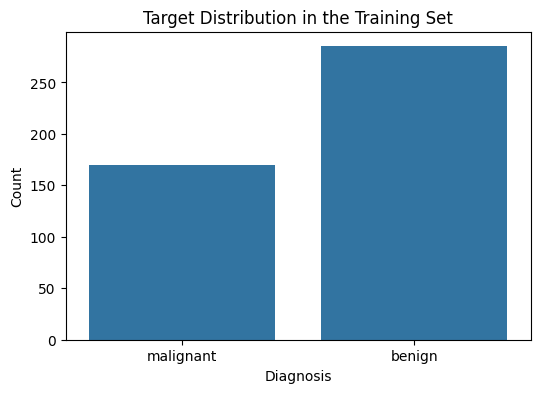

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x="diagnosis_label")
plt.title("Target Distribution in the Training Set")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

The training set contains both benign and malignant cases. The classes are not perfectly balanced, but both classes are well represented. This confirms why stratification was useful during the train/test split.

Anlysis of features of interest

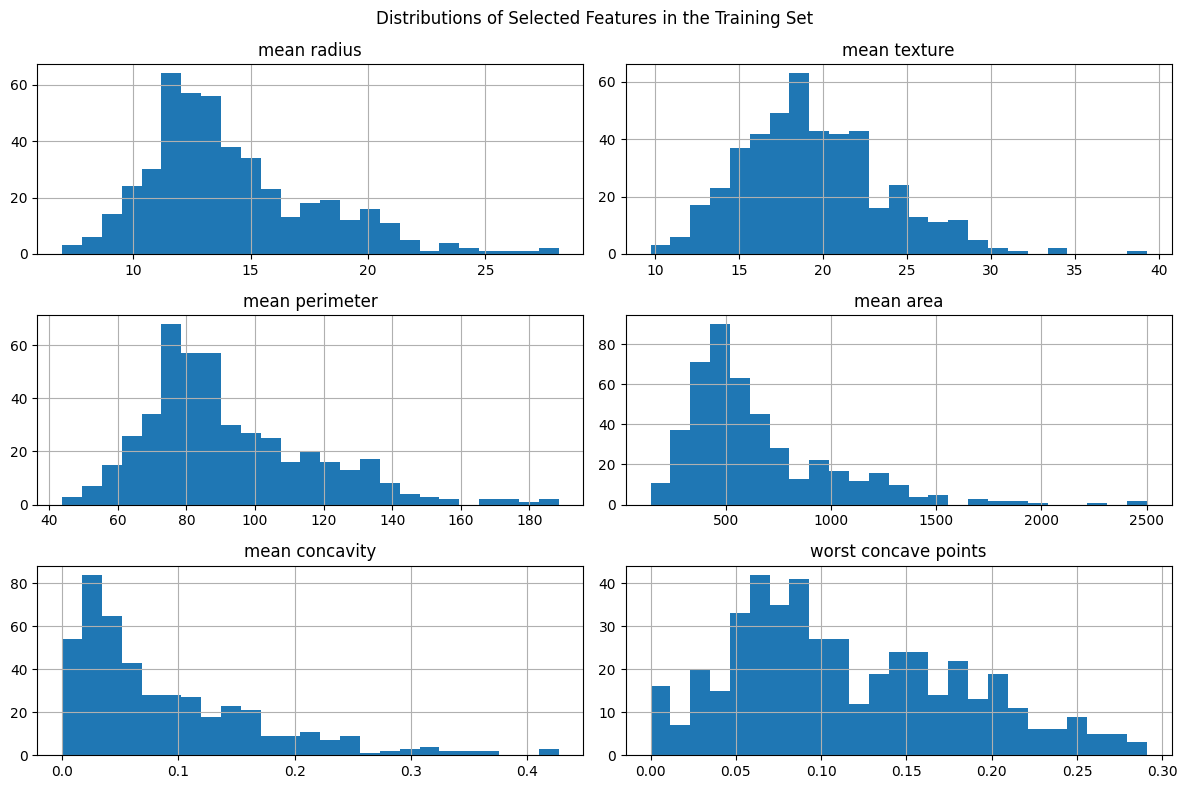

In [ ]:
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean concavity",
    "worst concave points"
]

# Histograms of selected features
train_df[selected_features].hist(figsize=(12, 8), bins=25)
plt.suptitle("Distributions of Selected Features in the Training Set")
plt.tight_layout()
plt.show()

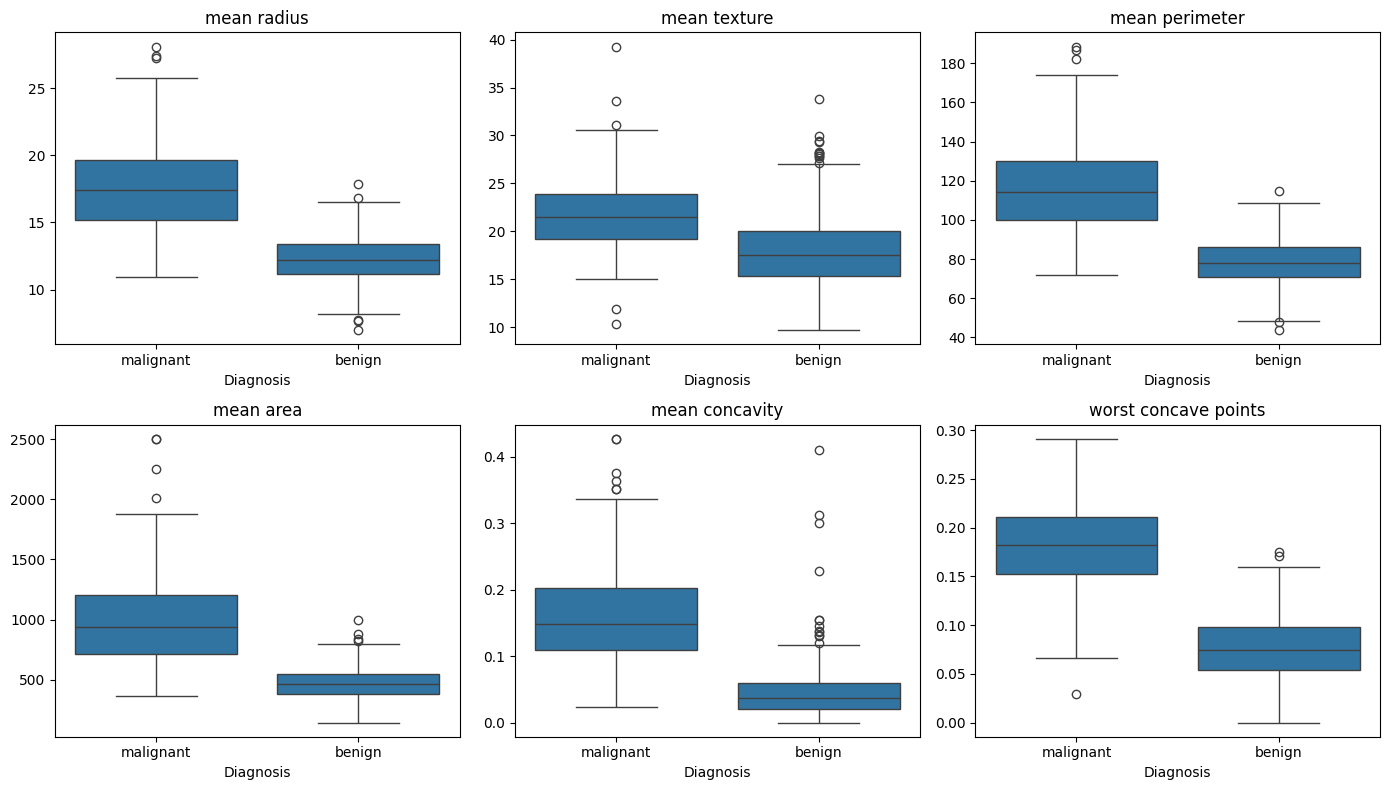

In [ ]:
plt.figure(figsize=(14, 8))

for i, feature in enumerate(selected_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=train_df, x="diagnosis_label", y=feature)
    plt.title(feature)
    plt.xlabel("Diagnosis")
    plt.ylabel("")

plt.tight_layout()
plt.show()

The histograms show that the selected features have very different numerical scales. Area-related variables have values in the hundreds or thousands, while concavity-related variables are measured on a much smaller scale. This shows the need for standardization before applying PCA, t-SNE, clustering, kNN, logistic regression, and SVM.

Several features are biased to the right and contain large values or possible outliers. These observations are not removed automatically because they may correspond to real tumor characteristics rather than data errors.

The boxplots show clear differences between benign and malignant tumors. Malignant tumors tend to have higher values of radius, perimeter, area, concavity, and worst concave points. These differences suggest that the input features contain meaningful information for distinguishing between the two diagnostic classes.

Mean texture shows more overlap between the two classes, so it appears less discriminative on its own than size and concavity-related features.

### Feature Correlation Matrix

Before applying PCA, we inspect the correlations between input features. This helps us understand whether some variables contain redundant information.

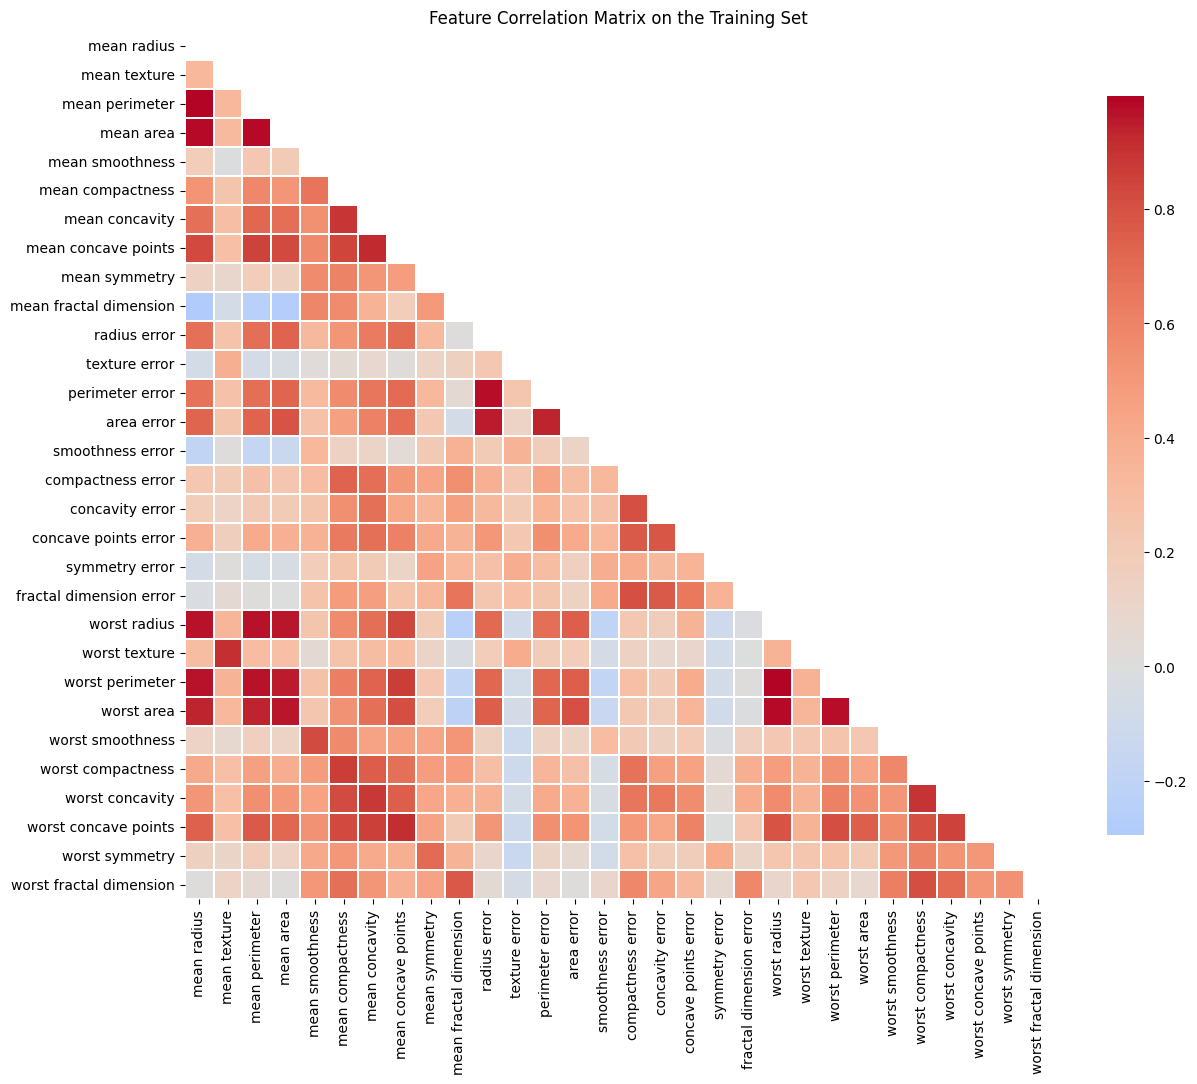

In [ ]:
# Correlation matrix between input features in the training set
corr_matrix = X_train.corr()

# Create mask to show only one triangle of the matrix
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8}
)

plt.title("Feature Correlation Matrix on the Training Set")
plt.show()

In [ ]:
# Strongest feature-feature correlations
corr_pairs = corr_matrix.abs().unstack().sort_values(ascending=False)

# Remove self-correlations
corr_pairs = corr_pairs[corr_pairs < 1]

# Remove duplicated pairs
corr_pairs = corr_pairs.drop_duplicates()

display(corr_pairs.head(15))

mean radius      mean perimeter     0.997815
worst perimeter  worst radius       0.993719
mean area        mean radius        0.986740
mean perimeter   mean area          0.985960
worst area       worst radius       0.983107
                 worst perimeter    0.976665
perimeter error  radius error       0.974705
worst perimeter  mean perimeter     0.970006
worst radius     mean perimeter     0.969332
mean radius      worst radius       0.969256
worst perimeter  mean radius        0.964439
worst radius     mean area          0.960725
worst area       mean area          0.958177
worst perimeter  mean area          0.956714
area error       radius error       0.951558
dtype: float64

The correlation matrix shows that several features are extremely correlated, especially size-related variables such as radius, perimeter, and area. This indicates that the dataset contains redundant information: multiple features describe very similar aspects of the tumor cell nuclei.

At this stage, we do not remove these variables manually. The main analysis will first use the full feature set to preserve all available information. However, this redundancy motivates the use of PCA, which provides a systematic way to compress correlated variables into fewer principal components. Later, we can compare supervised models trained on the original features with models trained on PCA-transformed or correlation-reduced features.

In [ ]:
# Correlation between each feature and the diagnosis
correlations = (
    train_df
    .drop(columns=["diagnosis_label"])
    .corr()["diagnosis"]
    .drop("diagnosis")
)

correlations_sorted = correlations.abs().sort_values(ascending=False)

display(correlations_sorted.head(10))

,diagnosis
worst concave points,0.786306
worst perimeter,0.782881
worst radius,0.777602
mean concave points,0.775737
mean perimeter,0.740027
worst area,0.731761
mean radius,0.728160
mean area,0.703893
mean concavity,0.683688
worst concavity,0.643116


### Correlation with Diagnosis

To better understand which variables are most associated with the diagnosis, we compute the correlation between each numerical feature and the target variable. This is used only for exploratory interpretation, not for automatic feature selection.

In [ ]:
# Correlation between each feature and the diagnosis
correlations = (
    train_df
    .drop(columns=["diagnosis_label"])
    .corr()["diagnosis"]
    .drop("diagnosis")
)

correlations_sorted = correlations.abs().sort_values(ascending=False)

display(correlations_sorted.head(10))

,diagnosis
worst concave points,0.786306
worst perimeter,0.782881
worst radius,0.777602
mean concave points,0.775737
mean perimeter,0.740027
worst area,0.731761
mean radius,0.728160
mean area,0.703893
mean concavity,0.683688
worst concavity,0.643116


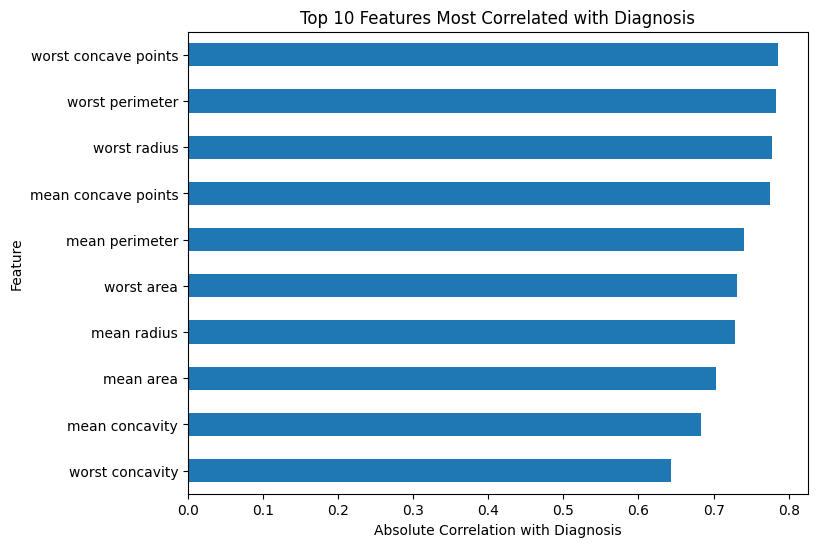

In [ ]:
plt.figure(figsize=(8, 6))

correlations_sorted.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Features Most Correlated with Diagnosis")
plt.xlabel("Absolute Correlation with Diagnosis")
plt.ylabel("Feature")
plt.show()

### Feature Scales Before Standardization

Before applying PCA, t-SNE, clustering, or supervised models, we inspect the numerical scales of the features.

In [ ]:
# Summary of feature scales before standardization
scale_summary = X_train.describe().loc[["mean", "std", "min", "max"]].T

display(scale_summary.sort_values("std", ascending=False).head(10))

,mean,std,min,max
worst area,890.569231,582.346181,185.200,4254.00
mean area,659.578242,360.418686,143.500,2501.00
area error,41.279103,48.384174,6.802,542.20
worst perimeter,107.860484,34.176019,50.410,251.20
mean perimeter,92.215868,24.717118,43.790,188.50
worst texture,25.904879,6.079532,12.020,49.54
worst radius,16.351514,4.901037,7.930,36.04
mean texture,19.417692,4.290653,9.710,39.28
mean radius,14.166077,3.579081,6.981,28.11
perimeter error,2.911569,2.123119,0.757,21.98


The scale summary confirms that the features have very different numerical magnitudes. For example, area-related features have much larger values and standard deviations than variables such as smoothness, concavity, or symmetry.

Therefore, standardization is necessary before applying PCA, t-SNE, clustering, kNN, logistic regression, and SVM. Without scaling, variables with larger numerical ranges could dominate methods based on variance, distances, dot products, or margins.

### EDA Summary

The exploratory analysis shows that the dataset is clean and contains meaningful patterns related to the diagnosis. The selected boxplots show that malignant tumors generally have larger and more irregular cell nuclei, especially in features related to radius, perimeter, area, concavity, and concave points.

The features have very different numerical scales, so standardization is required before using dimensionality reduction, clustering, and supervised learning models.

## Preprocessing for Unsupervised Learning

For PCA, t-SNE, and clustering, the features are standardized using only the training data. The scaler is fitted on the training set and then applied to the test set. This avoids data leakage.

For supervised models later, standardization will be included inside each Pipeline.

In [ ]:
from sklearn.preprocessing import StandardScaler

# This scaler is used for unsupervised exploration only:
# PCA, t-SNE, and clustering.
# For supervised models, scaling will be included inside each Pipeline.

scaler_unsup = StandardScaler()

# Fit scaler only on the training data
X_train_scaled = scaler_unsup.fit_transform(X_train)

# Transform test data using the scaler fitted on training data
X_test_scaled = scaler_unsup.transform(X_test)

# Convert back to DataFrames for easier inspection
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training set shape:", X_train_scaled.shape)
print("Scaled test set shape:", X_test_scaled.shape)

Scaled training set shape: (455, 30)
Scaled test set shape: (114, 30)


In [ ]:
# Check mean and standard deviation after scaling
scaling_check = X_train_scaled.describe().loc[["mean", "std"]]

display(scaling_check)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
mean,-1.737316e-16,3.904081e-16,4.704418e-16,-1.171224e-16,7.242070e-16,-5.075305e-17,-4.489693e-17,2.928061e-17,2.342449e-17,3.669836e-16,1.678755e-16,-8.979386e-17,-2.498612e-16,1.444510e-16,-1.561632e-16,-1.561632e-17,4.684897e-17,-1.405469e-16,8.588978e-17,-2.342449e-17,-3.962642e-16,2.186285e-16,-2.986622e-16,-1.561632e-17,-1.522592e-16,-1.132183e-16,-4.489693e-17,3.025663e-17,-4.841060e-16,3.006142e-16
std,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00,1.001101e+00


After standardization, the training features have mean approximately 0 and standard deviation approximately 1. Small deviations from exact values are due to numerical precision and the definition of standard deviation used by pandas.

## Unsupervised Learning I: Principal Component Analysis (PCA)

PCA is used to reduce the dimensionality of the dataset while preserving as much information of the variance as possible. Since the original dataset has 30 numerical features, PCA allows us to visualize the data in two dimensions using the first two principal components.

The diagnosis labels are not used to fit PCA. They are only used after the projection to interpret whether the low-dimensional structure is related to the known benign/malignant classes.

In [ ]:
from sklearn.decomposition import PCA

# PCA with 2 components for visualization
pca_2 = PCA(n_components=2, random_state=RANDOM_STATE)

# Fit PCA only on the scaled training data
X_train_pca_2 = pca_2.fit_transform(X_train_scaled)

# Create dataframe for visualization
pca_train_df = pd.DataFrame(
    X_train_pca_2,
    columns=["PC1", "PC2"],
    index=X_train.index
)

# Keep original index as sample_id
pca_train_df = pca_train_df.reset_index().rename(columns={"index": "sample_id"})

# Reset y_train so it aligns by position
pca_train_df["diagnosis"] = y_train.reset_index(drop=True)

pca_train_df["diagnosis_label"] = pca_train_df["diagnosis"].map({
    1: "malignant",
    0: "benign"
})

display(pca_train_df.head())

,sample_id,PC1,PC2,diagnosis,diagnosis_label
0,10,-0.875937,-2.571309,1,malignant
1,170,-2.505128,0.192453,0,benign
2,407,-1.354117,0.417851,0,benign
3,430,4.854091,3.017576,1,malignant
4,27,2.926225,-1.866546,1,malignant


The PCA dataframe contains the first two principal components for each training sample. The original row index is stored as `sample_id` to preserve traceability. The diagnosis labels are added only for visualization and interpretation; they were not used to fit PCA.

In [ ]:
# Explained variance by the first two principal components
print("Explained variance ratio:")
print(pca_2.explained_variance_ratio_)

print("\nTotal variance explained by PC1 and PC2:")
print(pca_2.explained_variance_ratio_.sum())

Explained variance ratio:
[0.44593522 0.18545255]

Total variance explained by PC1 and PC2:
0.631387776559559


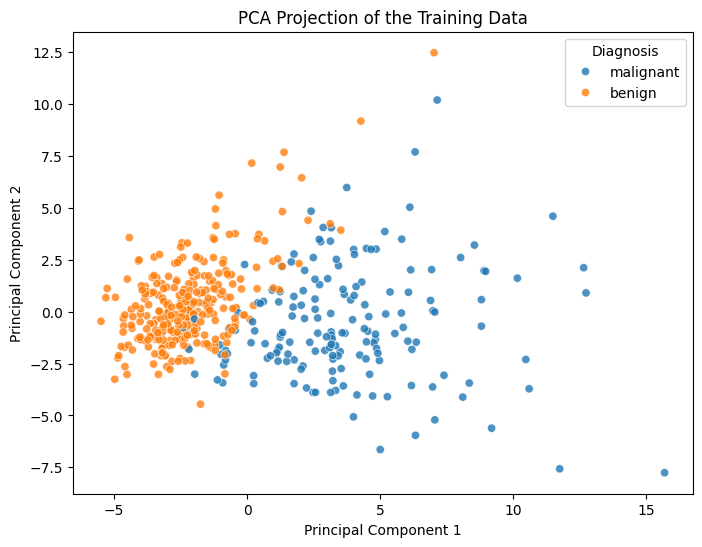

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_train_df,
    x="PC1",
    y="PC2",
    hue="diagnosis_label",
    alpha=0.8
)

plt.title("PCA Projection of the Training Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Diagnosis")
plt.show()

The PCA projection shows a clear partial separation between benign and malignant tumors. Benign samples are concentrated mostly on the left side of the plot, while malignant samples tend to appear toward higher values of the first principal component.

Since PCA was fitted without using the diagnosis labels, this separation suggests that the original numerical measurements contain an intrinsic structure related to the diagnosis. The separation is not perfect, because some samples overlap in the central region, but the global trend is clearly visible.

The PCA projection shows the training samples represented in two dimensions. PCA was fitted without using the diagnosis labels; the labels are only used here for visualization. Therefore, any visible separation between benign and malignant tumors suggests that the class structure is reflected in the geometry of the input features.

Most of the class separation appears along the first principal component. This suggests that PC1 captures a dominant source of variation related to tumor characteristics, likely combining information from size and boundary-irregularity features such as radius, perimeter, area, concavity, and concave points.

However, the PCA plot also shows overlap between the two classes. This means that two principal components are not sufficient to perfectly separate benign and malignant tumors. A supervised model may still benefit from using the full feature space or more principal components.

In [ ]:
# PCA with all components to study cumulative explained variance
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

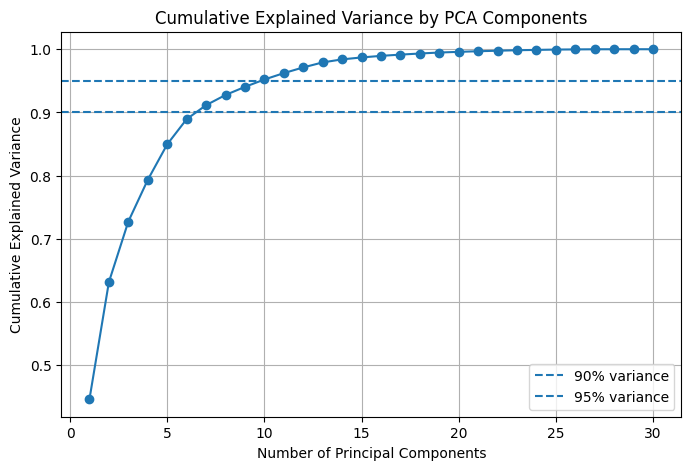

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.axhline(y=0.95, linestyle="--", label="95% variance")

plt.title("Cumulative Explained Variance by PCA Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of components needed for 90% variance:", n_components_90)
print("Number of components needed for 95% variance:", n_components_95)

Number of components needed for 90% variance: 7
Number of components needed for 95% variance: 10


The PCA cumulative explained variance analysis shows that 7 principal components are needed to retain at least 90% of the variance, while 10 principal components are needed to retain at least 95% of the variance.

This means that the original 30-dimensional dataset can be reduced substantially while preserving most of its variability. The first two components are useful for visualization, but more components are needed to keep most of the information contained in the original features.

## Unsupervised Learning II: t-SNE

After PCA, we apply t-SNE to obtain a nonlinear two-dimensional visualization of the training data. PCA focuses on preserving directions of maximum variance, while t-SNE focuses more on preserving local neighborhoods.

The diagnosis labels are not used to compute t-SNE. They are added only afterward to interpret whether the structure discovered by t-SNE is related to the benign/malignant classes.

Because t-SNE depends on hyperparameters, especially `perplexity`, we test several values instead of relying on a single visualization. The goal is not to choose the plot that looks best, but to check whether the overall structure is reasonably stable across different neighborhood scales.

In [ ]:
from sklearn.manifold import TSNE

# Different perplexity values to compare
# Small values focus on very local structure.
# Larger values consider broader neighborhoods.
perplexities = [5, 10, 30, 50]

tsne_results = {}

for perplexity in perplexities:
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate="auto",
        init="pca",
        max_iter=1000,
        random_state=RANDOM_STATE
    )

    # Fit t-SNE only on the scaled training data
    X_train_tsne = tsne.fit_transform(X_train_scaled)

    # Create dataframe for visualization
    tsne_df = pd.DataFrame(
        X_train_tsne,
        columns=["tSNE1", "tSNE2"]
    )

    # Keep original sample ids for traceability
    tsne_df["sample_id"] = X_train.index.to_numpy()

    # Add labels only for visualization
    tsne_df["diagnosis"] = y_train.reset_index(drop=True)
    tsne_df["diagnosis_label"] = tsne_df["diagnosis"].map({
        1: "malignant",
        0: "benign"
    })

    tsne_results[perplexity] = tsne_df

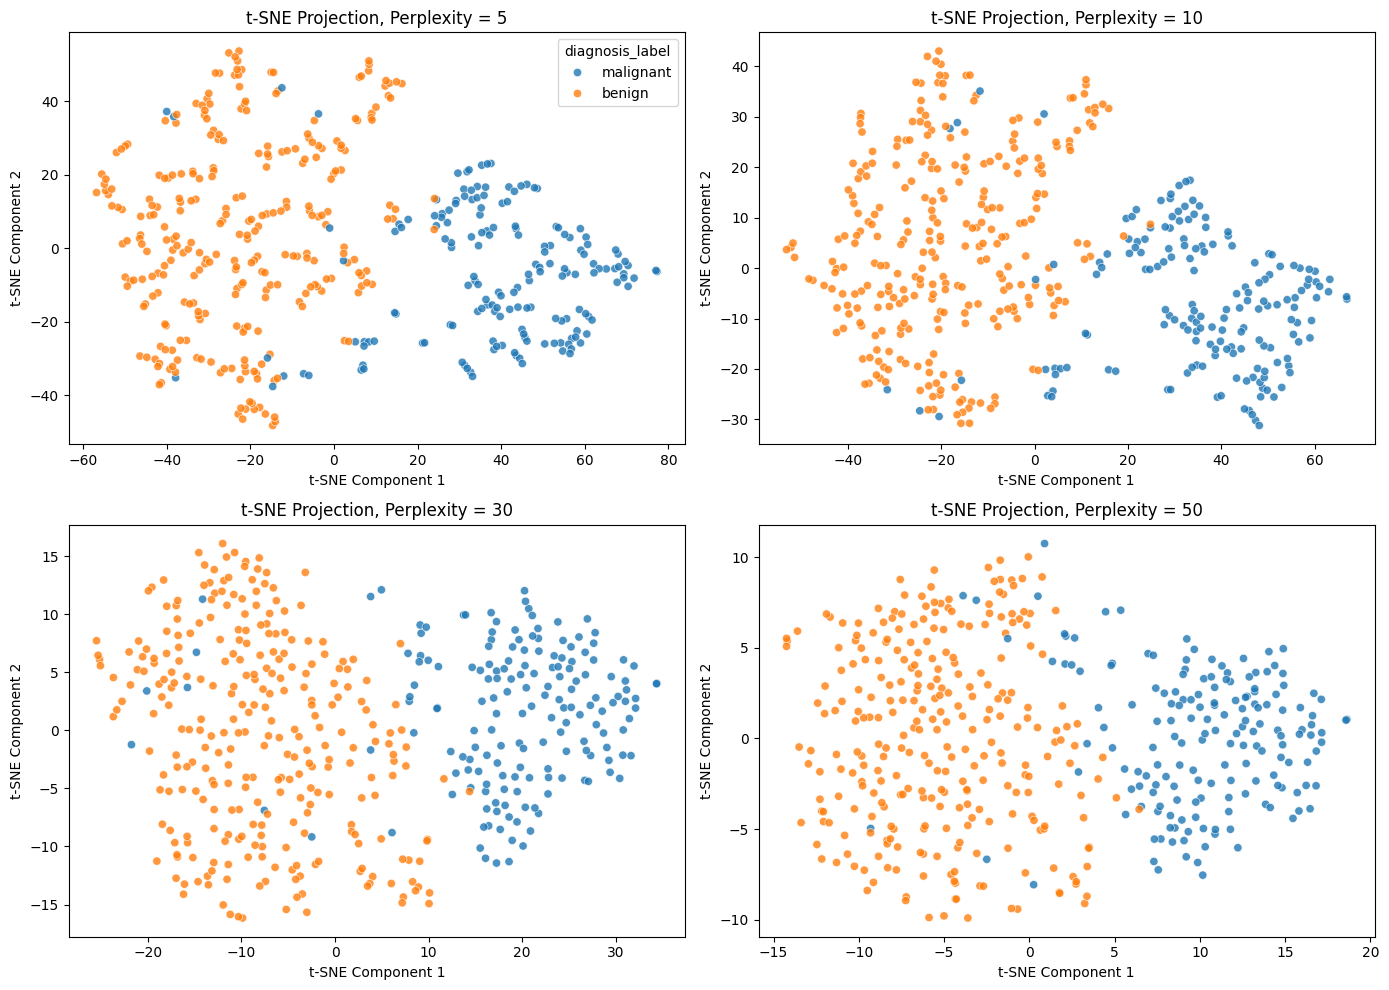

In [ ]:
plt.figure(figsize=(14, 10))

for i, perplexity in enumerate(perplexities, 1):
    plt.subplot(2, 2, i)

    sns.scatterplot(
        data=tsne_results[perplexity],
        x="tSNE1",
        y="tSNE2",
        hue="diagnosis_label",
        alpha=0.8,
        legend=(i == 1)
    )

    plt.title(f"t-SNE Projection, Perplexity = {perplexity}")
    plt.xlabel("t-SNE Component 1")
    plt.ylabel("t-SNE Component 2")

plt.tight_layout()
plt.show()

The t-SNE visualizations show that the overall benign/malignant structure is reasonably stable across different perplexity values. For low perplexity values, such as 5 and 10, the visualization is more fragmented into small local groups. For higher values, such as 30 and 50, the structure becomes smoother and more global.

Across all tested perplexity values, benign samples are mostly concentrated on one side of the plot, while malignant samples appear mostly on the other side. This suggests that the local neighborhood structure of the feature space is strongly related to the diagnosis.

Perplexity = 30 is used as the main visualization because it provides a balanced view: it is less fragmented than the low-perplexity plots, while still preserving a clear separation between the two diagnostic groups. However, t-SNE remains an exploratory method. Its axes are not directly interpretable, and the visualization should not be treated as a supervised classification result.

## Unsupervised Learning III: Clustering

After PCA and t-SNE, we apply clustering methods to investigate whether the training data naturally forms groups. Since the dataset has two known diagnostic classes, benign and malignant, we first use two clusters.

The clustering algorithms are fitted without using the diagnosis labels. The labels are used only afterward to interpret whether the discovered clusters correspond to meaningful diagnostic groups.

### K-Means Clustering

K-Means partitions the data into a fixed number of clusters by assigning each point to the nearest cluster center. Since the known diagnosis has two classes, we start with `n_clusters = 2`.

K-Means is sensitive to feature scale, so we apply it to the standardized training data.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# K-Means with 2 clusters
kmeans = KMeans(
    n_clusters=2,
    random_state=RANDOM_STATE,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(X_train_scaled)

# Store results
cluster_df = train_df.copy()
cluster_df["kmeans_cluster"] = kmeans_labels

display(cluster_df[["diagnosis", "diagnosis_label", "kmeans_cluster"]].head())

,diagnosis,diagnosis_label,kmeans_cluster
10,1,malignant,0
170,0,benign,0
407,0,benign,0
430,1,malignant,1
27,1,malignant,1


In [ ]:
# Compare K-Means clusters with true diagnosis labels
kmeans_crosstab = pd.crosstab(
    cluster_df["diagnosis_label"],
    cluster_df["kmeans_cluster"],
    rownames=["Diagnosis"],
    colnames=["K-Means Cluster"]
)

display(kmeans_crosstab)

K-Means Cluster,0,1
Diagnosis,,
benign,270,15
malignant,27,143


The K-Means crosstab shows that the clusters are strongly related to the true diagnosis labels. Cluster 0 contains mostly benign samples, while Cluster 1 contains mostly malignant samples.

This is important because K-Means did not use the diagnosis labels during fitting. The alignment between clusters and labels suggests that the benign/malignant distinction is reflected in the geometry of the standardized feature space.

However, the clustering is not perfect. Some malignant samples are grouped with the mostly benign cluster, and some benign samples are grouped with the mostly malignant cluster. Therefore, clustering reveals meaningful structure, but supervised learning is still necessary for reliable prediction.

In [ ]:
from sklearn.metrics import adjusted_rand_score, silhouette_score

# External validation: compares clusters with true labels
kmeans_ari = adjusted_rand_score(y_train, kmeans_labels)

# Internal validation: measures cluster separation without using labels
kmeans_silhouette = silhouette_score(X_train_scaled, kmeans_labels)

print("K-Means Adjusted Rand Index:", kmeans_ari)
print("K-Means Silhouette Score:", kmeans_silhouette)

K-Means Adjusted Rand Index: 0.6622066991321112
K-Means Silhouette Score: 0.3432356203274449


To evaluate the clustering, we use two complementary metrics.

The Adjusted Rand Index compares the K-Means clusters with the true diagnosis labels. This is an external validation measure because it uses information that was not given to the clustering algorithm during fitting.

The silhouette score evaluates the geometric quality of the clusters without using the diagnosis labels. It measures whether samples are closer to points in their own cluster than to points in other clusters.

Together, these metrics help distinguish two questions: whether the clusters correspond to the medical diagnosis, and whether the clusters are well separated in the feature space.

Visualizing k means in PCA space

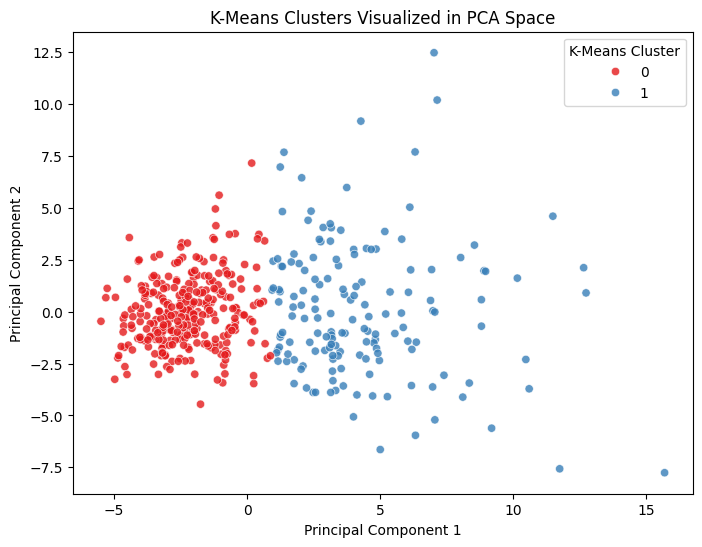

In [ ]:
# Add K-Means labels to PCA dataframe
pca_train_df["kmeans_cluster"] = kmeans_labels

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_train_df,
    x="PC1",
    y="PC2",
    hue="kmeans_cluster",
    palette="Set1",
    alpha=0.8
)

plt.title("K-Means Clusters Visualized in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="K-Means Cluster")
plt.show()

The K-Means clusters are visualized in the PCA space to understand how the algorithm partitions the data. The plot shows whether the clusters align with the main low-dimensional structure discovered by PCA.

K-Means separates the data mainly along the same direction observed in the PCA projection. This suggests that the dominant low-dimensional structure of the dataset is strongly related to the clusters found by K-Means.

### Gaussian Mixture Model Clustering

A Gaussian Mixture Model assumes that the data is generated from a mixture of Gaussian distributions. Compared with K-Means, GMM is more flexible because it can model clusters with different covariance structures.

As with K-Means, the model is fitted without using the diagnosis labels. The labels are used only afterward for interpretation.

In [ ]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(
    n_components=2,
    covariance_type="full",
    random_state=RANDOM_STATE,
    n_init=20
)

gmm_labels = gmm.fit_predict(X_train_scaled)

cluster_df["gmm_cluster"] = gmm_labels

display(cluster_df[["diagnosis", "diagnosis_label", "kmeans_cluster", "gmm_cluster"]].head())

,diagnosis,diagnosis_label,kmeans_cluster,gmm_cluster
10,1,malignant,0,0
170,0,benign,0,1
407,0,benign,0,1
430,1,malignant,1,0
27,1,malignant,1,0


In [ ]:
# Compare GMM clusters with true diagnosis labels
gmm_crosstab = pd.crosstab(
    cluster_df["diagnosis_label"],
    cluster_df["gmm_cluster"],
    rownames=["Diagnosis"],
    colnames=["GMM Cluster"]
)

display(gmm_crosstab)

GMM Cluster,0,1
Diagnosis,,
benign,18,267
malignant,158,12


The GMM crosstab compares the Gaussian mixture clusters with the true diagnosis labels. Since GMM is an unsupervised method, the diagnosis labels were not used during fitting and the cluster numbers are arbitrary.

The important question is whether one cluster contains mostly benign samples and the other contains mostly malignant samples. If this happens, it suggests that the clusters discovered by GMM are meaningfully related to the known diagnosis classes.

In [ ]:
from sklearn.metrics import adjusted_rand_score, silhouette_score

# External validation: agreement with the true diagnosis labels
gmm_ari = adjusted_rand_score(y_train, gmm_labels)

# Internal validation: geometric cluster separation without using labels
gmm_silhouette = silhouette_score(X_train_scaled, gmm_labels)

print("GMM Adjusted Rand Index:", gmm_ari)
print("GMM Silhouette Score:", gmm_silhouette)

GMM Adjusted Rand Index: 0.7523578055301555
GMM Silhouette Score: 0.3142331086647761


The GMM crosstab shows a strong relationship between the discovered clusters and the true diagnosis labels. Cluster 1 contains mostly benign samples, while Cluster 0 contains mostly malignant samples.

This is important because GMM did not use the diagnosis labels during fitting. Therefore, the alignment between clusters and labels suggests that the benign/malignant distinction is strongly reflected in the geometry of the standardized feature space.

Compared with K-Means, GMM appears to recover the diagnostic structure more accurately, which is consistent with its higher Adjusted Rand Index.

The clustering comparison also shows an interesting trade-off. GMM achieved a higher Adjusted Rand Index than K-Means, meaning that its clusters agree more strongly with the true benign/malignant diagnosis labels. This suggests that GMM better captures the diagnostic structure of the dataset.

However, K-Means achieved a slightly higher silhouette score. This means that K-Means produced clusters that are somewhat more compact or geometrically separated according to an internal clustering criterion.

These results are not contradictory. The Adjusted Rand Index uses the true diagnosis labels, while the silhouette score only evaluates geometric separation without using labels. Therefore, GMM appears better at recovering the medical class structure, while K-Means produces slightly cleaner geometric clusters.

Overall, both clustering methods reveal meaningful structure related to the diagnosis, supporting the conclusions from PCA and t-SNE. However, neither clustering method perfectly reproduces the diagnosis, so supervised learning is still necessary for reliable prediction.

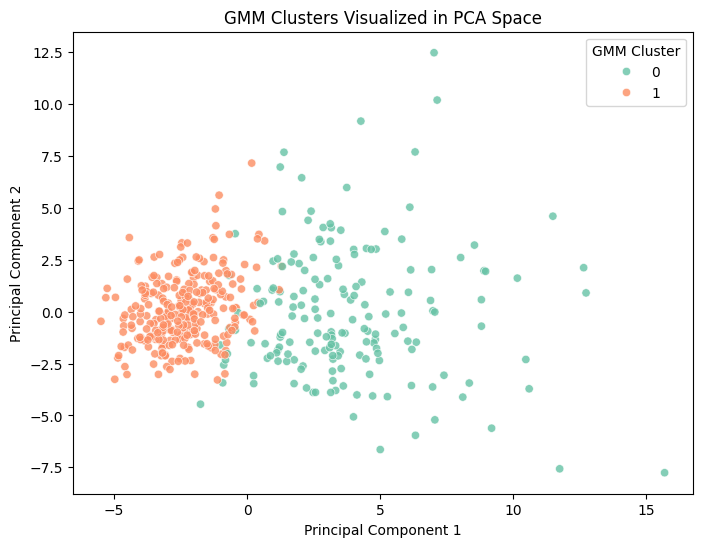

In [ ]:
# Add GMM labels to PCA dataframe
pca_train_df["gmm_cluster"] = gmm_labels

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_train_df,
    x="PC1",
    y="PC2",
    hue="gmm_cluster",
    palette="Set2",
    alpha=0.8
)

plt.title("GMM Clusters Visualized in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="GMM Cluster")
plt.show()

The GMM clusters are mainly separated along the first principal component. One cluster is concentrated on the left side of the PCA space, while the other cluster is spread toward higher values of PC1.

This agrees with the previous PCA visualization, where benign and malignant tumors were also mostly separated along PC1. The overlap in the central region shows that the separation is not perfect, which explains why the clustering does not exactly reproduce the diagnosis labels.

Compared with K-Means, GMM achieved a higher Adjusted Rand Index, suggesting that it better captures the benign/malignant structure. However, its slightly lower silhouette score indicates that the clusters are less compact geometrically.

In [ ]:
clustering_results = pd.DataFrame({
    "Method": ["K-Means", "Gaussian Mixture Model"],
    "Adjusted Rand Index": [kmeans_ari, gmm_ari],
    "Silhouette Score": [kmeans_silhouette, gmm_silhouette]
})

display(clustering_results)

,Method,Adjusted Rand Index,Silhouette Score
0,K-Means,0.662207,0.343236
1,Gaussian Mixture Model,0.752358,0.314233


## Supervised Learning

After the unsupervised analysis, we now build supervised classification models to predict whether a tumor is malignant or benign.

We compare two types of feature representations:

1. The original 30 numerical features.
2. PCA-transformed features inside the pipeline.

This comparison connects the supervised and unsupervised parts of the project. Since the correlation matrix showed strong redundancy and PCA showed that 7 components retain 90% of the variance and 10 components retain 95%, we test whether dimensionality reduction preserves predictive performance.

All preprocessing is included inside the pipelines to avoid data leakage during cross-validation.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
# Cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Main scoring metric for model selection
scoring = "f1"

We use stratified 5-fold cross-validation on the training set. Stratification keeps the benign/malignant proportions similar across folds.

The main model-selection metric is F1-score. Since the positive class is malignant, F1 balances precision and recall for malignant tumor detection. Recall will also be inspected carefully because missing malignant cases is medically more serious than incorrectly flagging benign cases.

In [ ]:
def run_grid_search(model_name, pipeline, param_grid):
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=scoring,
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    grid_search.fit(X_train, y_train)

    print(f"Model: {model_name}")
    print("Best parameters:", grid_search.best_params_)
    print("Best CV F1-score:", grid_search.best_score_)

    return grid_search

### Models with Original Features

We first train the supervised models using the original 30 input features. Each model is built as a pipeline containing standardization followed by the classifier.

The models are tuned using cross-validation on the training set only. The test set remains untouched for final evaluation.

In [ ]:
log_reg_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

log_reg_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

log_reg_search = run_grid_search(
    "Logistic Regression - Original Features",
    log_reg_pipe,
    log_reg_param_grid
)

Model: Logistic Regression - Original Features
Best parameters: {'model__C': 1}
Best CV F1-score: 0.9640480895915677


Logistic Regression achieved a high cross-validation F1-score using the original 30 features. The best value of `C` was 1, which corresponds to a moderate amount of regularization. This suggests that a linear model already performs very well on this dataset, consistent with the PCA visualization where benign and malignant samples were largely separated along the first principal component.

In [ ]:
svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

svm_search = run_grid_search(
    "SVM RBF - Original Features",
    svm_pipe,
    svm_param_grid
)

Model: SVM RBF - Original Features
Best parameters: {'model__C': 10, 'model__gamma': 'scale'}
Best CV F1-score: 0.9674103219883271


The SVM with RBF kernel achieved a slightly higher cross-validation F1-score than Logistic Regression. The best parameters were `C = 10` and `gamma = "scale"`.

This suggests that allowing a nonlinear decision boundary provides a small improvement over the linear baseline. However, the difference is not very large, which means that the dataset is already highly separable using a relatively simple model.

In [ ]:
knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"]
}

knn_search = run_grid_search(
    "kNN - Original Features",
    knn_pipe,
    knn_param_grid
)

Model: kNN - Original Features
Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best CV F1-score: 0.9632634032634033


The three original-feature models achieved very similar cross-validation F1-scores. SVM with RBF kernel performed slightly best, followed closely by Logistic Regression and kNN.

The small difference between Logistic Regression and SVM suggests that the dataset is already strongly separable with a relatively simple decision boundary, although the nonlinear SVM provides a small improvement. kNN also performed well, with the best result obtained using only 3 neighbors, indicating that local neighborhood structure is useful for classification.

In [ ]:
original_cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM RBF",
        "kNN"
    ],
    "Best CV F1": [
        log_reg_search.best_score_,
        svm_search.best_score_,
        knn_search.best_score_
    ],
    "Best Parameters": [
        log_reg_search.best_params_,
        svm_search.best_params_,
        knn_search.best_params_
    ]
})

display(original_cv_results.sort_values("Best CV F1", ascending=False))

,Model,Best CV F1,Best Parameters
1,SVM RBF,0.967410,"{'model__C': 10, 'model__gamma': 'scale'}"
0,Logistic Regression,0.964048,{'model__C': 1}
2,kNN,0.963263,"{'model__n_neighbors': 3, 'model__weights': 'u..."


### Models with PCA Features

We now repeat the supervised learning experiments using PCA inside the pipeline. This connects the supervised and unsupervised parts of the project.

The correlation matrix showed strong redundancy among several features, especially size-related variables. PCA also showed that 7 components retain at least 90% of the variance and 10 components retain at least 95%. Therefore, we test whether supervised models can maintain strong predictive performance using a lower-dimensional representation.

PCA is included inside the pipeline so that, during cross-validation, both scaling and PCA are fitted only on the training folds. This avoids data leakage.

In [ ]:
# PCA component values to test
# 2 components: connects with the PCA visualization
# 6 components: slightly more compressed than the 90% variance threshold
# 7 components: approximately 90% explained variance
# 10 components: approximately 95% explained variance
# 15 components: less aggressive dimensionality reduction

pca_components = [2, 6, 7, 10, 15]

We test several numbers of PCA components. The values 7 and 10 are included because they retain approximately 90% and 95% of the variance, respectively. We also include 2 components to connect with the PCA visualization, 6 components as a slightly more compressed representation, and 15 components as a less aggressive reduction.

In [ ]:
log_reg_pca_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

log_reg_pca_param_grid = {
    "pca__n_components": pca_components,
    "model__C": [0.01, 0.1, 1, 10, 100]
}

log_reg_pca_search = run_grid_search(
    "Logistic Regression - PCA Features",
    log_reg_pca_pipe,
    log_reg_pca_param_grid
)

Model: Logistic Regression - PCA Features
Best parameters: {'model__C': 1, 'pca__n_components': 10}
Best CV F1-score: 0.9670684013089632


In [ ]:
svm_pca_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

svm_pca_param_grid = {
    "pca__n_components": pca_components,
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

svm_pca_search = run_grid_search(
    "SVM RBF - PCA Features",
    svm_pca_pipe,
    svm_pca_param_grid
)

Model: SVM RBF - PCA Features
Best parameters: {'model__C': 10, 'model__gamma': 0.01, 'pca__n_components': 15}
Best CV F1-score: 0.9697549589713768


In [ ]:
knn_pca_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("model", KNeighborsClassifier())
])

knn_pca_param_grid = {
    "pca__n_components": pca_components,
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"]
}

knn_pca_search = run_grid_search(
    "kNN - PCA Features",
    knn_pca_pipe,
    knn_pca_param_grid
)

Model: kNN - PCA Features
Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform', 'pca__n_components': 6}
Best CV F1-score: 0.9639913554399946


In [ ]:
cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM RBF",
        "kNN",
        "Logistic Regression + PCA",
        "SVM RBF + PCA",
        "kNN + PCA"
    ],
    "Best CV F1": [
        log_reg_search.best_score_,
        svm_search.best_score_,
        knn_search.best_score_,
        log_reg_pca_search.best_score_,
        svm_pca_search.best_score_,
        knn_pca_search.best_score_
    ],
    "Best Parameters": [
        log_reg_search.best_params_,
        svm_search.best_params_,
        knn_search.best_params_,
        log_reg_pca_search.best_params_,
        svm_pca_search.best_params_,
        knn_pca_search.best_params_
    ]
})

display(cv_results.sort_values("Best CV F1", ascending=False))

,Model,Best CV F1,Best Parameters
4,SVM RBF + PCA,0.969755,"{'model__C': 10, 'model__gamma': 0.01, 'pca__n..."
1,SVM RBF,0.967410,"{'model__C': 10, 'model__gamma': 'scale'}"
3,Logistic Regression + PCA,0.967068,"{'model__C': 1, 'pca__n_components': 10}"
0,Logistic Regression,0.964048,{'model__C': 1}
5,kNN + PCA,0.963991,"{'model__n_neighbors': 3, 'model__weights': 'u..."
2,kNN,0.963263,"{'model__n_neighbors': 3, 'model__weights': 'u..."


Parameters full column

In [ ]:
for model_name, search in [
    ("Logistic Regression", log_reg_search),
    ("SVM RBF", svm_search),
    ("kNN", knn_search),
    ("Logistic Regression + PCA", log_reg_pca_search),
    ("SVM RBF + PCA", svm_pca_search),
    ("kNN + PCA", knn_pca_search)
]:
    print(model_name)
    print("Best CV F1:", search.best_score_)
    print("Best parameters:", search.best_params_)
    print()

Logistic Regression
Best CV F1: 0.9640480895915677
Best parameters: {'model__C': 1}

SVM RBF
Best CV F1: 0.9674103219883271
Best parameters: {'model__C': 10, 'model__gamma': 'scale'}

kNN
Best CV F1: 0.9632634032634033
Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}

Logistic Regression + PCA
Best CV F1: 0.9670684013089632
Best parameters: {'model__C': 1, 'pca__n_components': 10}

SVM RBF + PCA
Best CV F1: 0.9697549589713768
Best parameters: {'model__C': 10, 'model__gamma': 0.01, 'pca__n_components': 15}

kNN + PCA
Best CV F1: 0.9639913554399946
Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform', 'pca__n_components': 6}



The cross-validation results show that all supervised models achieved high F1-scores, indicating that the diagnosis is highly predictable from the numerical cell nucleus features.

The best model was SVM with RBF kernel and PCA, with a cross-validation F1-score of 0.970. This model slightly outperformed the SVM trained on the original features. Logistic Regression and kNN also performed similarly well, both with and without PCA.

The PCA versions performed slightly better than their original-feature counterparts. This suggests that PCA preserved the most relevant predictive information while reducing redundancy among highly correlated features. This result connects the supervised and unsupervised parts of the project: the lower-dimensional structure discovered by PCA is not only useful for visualization, but also for prediction.

However, the differences between models are small. This means that the dataset is already strongly separable, and even a linear model such as Logistic Regression performs very well.

In [ ]:
best_model = svm_pca_search.best_estimator_

print("Best model:")
print(best_model)

print("\nBest parameters:")
print(svm_pca_search.best_params_)

print("\nBest CV F1-score:")
print(svm_pca_search.best_score_)

Best model:
Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA(n_components=15)),
                ('model',
                 SVC(C=10, gamma=0.01, probability=True, random_state=42))])

Best parameters:
{'model__C': 10, 'model__gamma': 0.01, 'pca__n_components': 15}

Best CV F1-score:
0.9697549589713768


Based on cross-validation, the best model was the SVM with RBF kernel and PCA inside the pipeline. This model is selected for final evaluation on the untouched test set.

In [ ]:
y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]

In [ ]:
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)

test_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC AUC"],
    "Test Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

display(test_results)

,Metric,Test Score
0,Accuracy,0.982456
1,Precision,1.000000
2,Recall,0.952381
3,F1-score,0.975610
4,ROC AUC,0.996693


The final test metrics evaluate the selected model on data that was not used during model selection. Since malignant tumors are encoded as the positive class, recall is especially important because it measures how many malignant cases were correctly detected.

In [ ]:
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["benign", "malignant"]
))

              precision    recall  f1-score   support

      benign       0.97      1.00      0.99        72
   malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



The final model achieved very strong performance on the test set, with an accuracy of 0.98 and an F1-score of 0.98 for the malignant class. The precision for malignant tumors was 1.00, meaning that all samples predicted as malignant were actually malignant. The recall for malignant tumors was 0.95, meaning that the model detected most malignant cases, although a small number of malignant samples were still misclassified as benign.

In this medical context, recall for malignant tumors is especially important because false negatives correspond to malignant tumors incorrectly classified as benign.

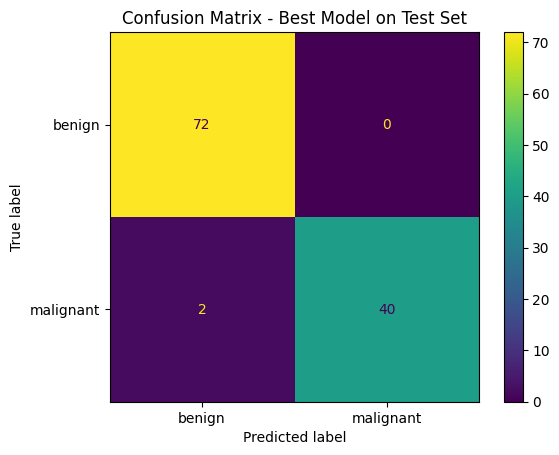

In [ ]:
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["benign", "malignant"]
)

disp.plot()
plt.title("Confusion Matrix - Best Model on Test Set")
plt.show()

The confusion matrix shows that the final model correctly classified most test samples. All benign tumors were correctly identified, while most malignant tumors were also detected.

The most important errors in this medical context are false negatives, which correspond to malignant tumors predicted as benign. The model produced a small number of false negatives, which explains why the recall for the malignant class is 0.95 instead of 1.00.

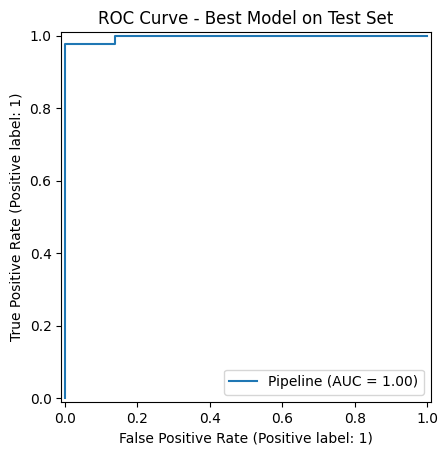

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test
)

plt.title("ROC Curve - Best Model on Test Set")
plt.show()

The ROC curve evaluates the model across different classification thresholds. This is useful because changing the decision threshold can trade precision for recall.

In this medical setting, a lower threshold could be considered if the goal is to reduce false negatives and detect as many malignant tumors as possible. However, this may also increase false positives.

### Final Test Evaluation

The selected model, SVM with RBF kernel and PCA inside the pipeline, achieved strong performance on the test set. The model obtained an accuracy of 0.98 and an F1-score of 0.98 for the malignant class.

The precision for malignant tumors was 1.00, meaning that all tumors predicted as malignant were actually malignant. The recall for malignant tumors was 0.95, meaning that the model detected most malignant cases, although a small number of malignant tumors were still misclassified as benign.

In this medical context, recall for malignant tumors is especially important because false negatives correspond to malignant tumors incorrectly classified as benign. Therefore, although the model performs very well overall, the remaining false negatives are the most important limitation.

### Using GMM Cluster Membership as Additional Features

The GMM clustering results showed a strong relationship between the discovered clusters and the true diagnosis labels. Therefore, we test whether cluster membership can provide useful additional information for supervised learning.

To avoid data leakage, the GMM transformation is included inside the pipeline. During cross-validation, the GMM is fitted only on the training fold and then used to generate cluster-membership probabilities for the validation fold.

Instead of using hard cluster labels, we use GMM probabilities: `P(cluster 0 | x)` and `P(cluster 1 | x)`. These probabilities give the supervised model a soft measure of how strongly each sample belongs to each cluster.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import FeatureUnion
from sklearn.mixture import GaussianMixture

class IdentityTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X


class GMMProbabilityTransformer(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        n_components=2,
        covariance_type="full",
        n_init=10,
        random_state=None
    ):
        self.n_components = n_components
        self.covariance_type = covariance_type
        self.n_init = n_init
        self.random_state = random_state

    def fit(self, X, y=None):
        self.gmm_ = GaussianMixture(
            n_components=self.n_components,
            covariance_type=self.covariance_type,
            n_init=self.n_init,
            random_state=self.random_state
        )
        self.gmm_.fit(X)
        return self

    def transform(self, X):
        return self.gmm_.predict_proba(X)

### SVM with GMM Cluster Membership Features

We now test whether the cluster structure discovered by GMM can improve supervised prediction. The model receives the original standardized features together with the GMM cluster-membership probabilities.

This transformation is included inside the pipeline to avoid data leakage during cross-validation.

In [ ]:
svm_gmm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("features", FeatureUnion([
        ("original_features", IdentityTransformer()),
        ("gmm_probabilities", GMMProbabilityTransformer(
            n_components=2,
            covariance_type="full",
            n_init=10,
            random_state=RANDOM_STATE
        ))
    ])),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

svm_gmm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

svm_gmm_search = run_grid_search(
    "SVM RBF - Original Features + GMM Probabilities",
    svm_gmm_pipe,
    svm_gmm_param_grid
)

Model: SVM RBF - Original Features + GMM Probabilities
Best parameters: {'model__C': 10, 'model__gamma': 'scale'}
Best CV F1-score: 0.9674103219883271


We train models using PCA aswell

In [ ]:
svm_pca_gmm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("features", FeatureUnion([
        ("pca_features", PCA()),
        ("gmm_probabilities", GMMProbabilityTransformer(
            n_components=2,
            covariance_type="full",
            n_init=10,
            random_state=RANDOM_STATE
        ))
    ])),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

svm_pca_gmm_param_grid = {
    "features__pca_features__n_components": pca_components,
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

svm_pca_gmm_search = run_grid_search(
    "SVM RBF - PCA Features + GMM Probabilities",
    svm_pca_gmm_pipe,
    svm_pca_gmm_param_grid
)

Model: SVM RBF - PCA Features + GMM Probabilities
Best parameters: {'features__pca_features__n_components': 15, 'model__C': 10, 'model__gamma': 0.01}
Best CV F1-score: 0.9694870546930897


In [ ]:
extended_cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM RBF",
        "kNN",
        "Logistic Regression + PCA",
        "SVM RBF + PCA",
        "kNN + PCA",
        "SVM RBF + GMM Probabilities",
        "SVM RBF + PCA + GMM Probabilities"
    ],
    "Best CV F1": [
        log_reg_search.best_score_,
        svm_search.best_score_,
        knn_search.best_score_,
        log_reg_pca_search.best_score_,
        svm_pca_search.best_score_,
        knn_pca_search.best_score_,
        svm_gmm_search.best_score_,
        svm_pca_gmm_search.best_score_
    ],
    "Best Parameters": [
        log_reg_search.best_params_,
        svm_search.best_params_,
        knn_search.best_params_,
        log_reg_pca_search.best_params_,
        svm_pca_search.best_params_,
        knn_pca_search.best_params_,
        svm_gmm_search.best_params_,
        svm_pca_gmm_search.best_params_
    ]
})

display(extended_cv_results.sort_values("Best CV F1", ascending=False))

,Model,Best CV F1,Best Parameters
4,SVM RBF + PCA,0.969755,"{'model__C': 10, 'model__gamma': 0.01, 'pca__n..."
7,SVM RBF + PCA + GMM Probabilities,0.969487,"{'features__pca_features__n_components': 15, '..."
1,SVM RBF,0.967410,"{'model__C': 10, 'model__gamma': 'scale'}"
6,SVM RBF + GMM Probabilities,0.967410,"{'model__C': 10, 'model__gamma': 'scale'}"
3,Logistic Regression + PCA,0.967068,"{'model__C': 1, 'pca__n_components': 10}"
0,Logistic Regression,0.964048,{'model__C': 1}
5,kNN + PCA,0.963991,"{'model__n_neighbors': 3, 'model__weights': 'u..."
2,kNN,0.963263,"{'model__n_neighbors': 3, 'model__weights': 'u..."


Because GMM clusters were strongly aligned with the diagnosis labels, we test whether cluster membership provides useful information for supervised learning.

We evaluate this only with SVM, since SVM was the strongest supervised model family in cross-validation. Two variants are tested: one using the original features plus GMM cluster probabilities, and another using PCA features plus GMM cluster probabilities.

This allows us to study whether the unsupervised cluster structure adds predictive value beyond the original features or beyond the PCA representation.

The extended comparison shows that adding GMM cluster-membership probabilities did not clearly improve supervised performance.

The best model remained SVM with RBF kernel and PCA, with a cross-validation F1-score of 0.970. Adding GMM probabilities to the PCA representation produced a very similar but slightly lower score. Adding GMM probabilities to the original SVM model resulted in essentially the same performance as the original SVM.

This suggests that the GMM clusters capture meaningful structure related to diagnosis, but this information is largely already present in the original features and in the PCA representation. Therefore, GMM cluster membership is useful for interpretation, but it does not provide substantial additional predictive value in this experiment.



The best model remained SVM with RBF kernel and PCA, with a cross-validation F1-score of 0.970.



## Connection Between Unsupervised and Supervised Learning

One of the main goals of this project is to connect the unsupervised analysis with the supervised prediction task.

In this project, the connection appears in several ways:

1. PCA revealed that the original 30-dimensional feature space contains strong lower-dimensional structure.
2. Supervised models with PCA inside the pipeline performed similarly or slightly better than models using the original features.
3. K-Means and GMM clusters were strongly related to the known benign/malignant labels.
4. GMM cluster-membership probabilities were tested as additional supervised features.
5. The final model errors can be analyzed using PCA coordinates and cluster assignments.

Together, these results show that the benign/malignant distinction is not only learned by supervised models, but is also visible in the unsupervised geometry of the data.

### Error Analysis Using PCA and GMM Clusters

To further connect the supervised and unsupervised parts of the project, we analyze the errors made by the final supervised model.

The goal is to see whether the misclassified samples appear in ambiguous regions of the PCA space or in clusters that are not perfectly aligned with the true diagnosis labels. This helps explain whether the model errors are related to the hidden structure discovered during the unsupervised analysis.

In [ ]:
# Select the best model based on cross-validation
best_model = svm_pca_search.best_estimator_

# Final predictions on the test set
y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]

# Convert y_test to array for safe alignment
y_test_array = np.asarray(y_test)

# Use the earlier unsupervised PCA projection for visualization
# pca_2 was fitted on X_train_scaled only
X_test_pca_2 = pca_2.transform(X_test_scaled)

# Create dataframe for test error analysis
test_analysis_df = pd.DataFrame(
    X_test_pca_2,
    columns=["PC1", "PC2"],
    index=X_test.index
)

# Keep original index as sample_id
test_analysis_df = test_analysis_df.reset_index().rename(columns={"index": "sample_id"})

# Add true labels, predictions, and probabilities
test_analysis_df["true_label"] = y_test_array
test_analysis_df["predicted_label"] = y_test_pred
test_analysis_df["malignant_probability"] = y_test_proba

# Convert labels to readable names
test_analysis_df["true_diagnosis"] = test_analysis_df["true_label"].map({
    0: "benign",
    1: "malignant"
})

test_analysis_df["predicted_diagnosis"] = test_analysis_df["predicted_label"].map({
    0: "benign",
    1: "malignant"
})

# Mark whether each prediction was correct
test_analysis_df["correct"] = (
    test_analysis_df["true_label"] == test_analysis_df["predicted_label"]
)

test_analysis_df["prediction_status"] = test_analysis_df["correct"].map({
    True: "correct",
    False: "incorrect"
})

# Assign GMM clusters to test samples using the GMM fitted on training data
test_analysis_df["gmm_cluster"] = gmm.predict(X_test_scaled)

# Add GMM cluster probabilities
gmm_test_probabilities = gmm.predict_proba(X_test_scaled)

test_analysis_df["gmm_prob_cluster_0"] = gmm_test_probabilities[:, 0]
test_analysis_df["gmm_prob_cluster_1"] = gmm_test_probabilities[:, 1]

display(test_analysis_df.head())

,sample_id,PC1,PC2,true_label,predicted_label,malignant_probability,true_diagnosis,predicted_diagnosis,correct,prediction_status,gmm_cluster,gmm_prob_cluster_0,gmm_prob_cluster_1
0,120,-2.954871,0.471308,0,0,0.000558,benign,benign,True,correct,1,7.800088e-12,1.000000e+00
1,250,6.892485,-2.047321,1,1,1.000000,malignant,malignant,True,correct,0,1.000000e+00,9.239765e-269
2,375,-0.125826,-0.058798,0,0,0.057791,benign,benign,True,correct,0,6.814210e-01,3.185790e-01
3,99,0.586226,0.666002,1,0,0.377411,malignant,benign,False,incorrect,1,1.346142e-05,9.999865e-01
4,455,-1.868729,-1.530491,0,0,0.217285,benign,benign,True,correct,1,1.736327e-10,1.000000e+00


In [ ]:
# Display only misclassified test samples
misclassified_df = test_analysis_df[test_analysis_df["correct"] == False]

display(misclassified_df)

,sample_id,PC1,PC2,true_label,predicted_label,malignant_probability,true_diagnosis,predicted_diagnosis,correct,prediction_status,gmm_cluster,gmm_prob_cluster_0,gmm_prob_cluster_1
3,99,0.586226,0.666002,1,0,0.377411,malignant,benign,False,incorrect,1,0.000013,0.999987
16,73,-0.397061,0.189557,1,0,0.060148,malignant,benign,False,incorrect,1,0.152005,0.847995


The table above shows only the test samples misclassified by the final model. For each error, we inspect the true diagnosis, predicted diagnosis, malignant probability, PCA coordinates, GMM cluster assignment, and GMM cluster probabilities.

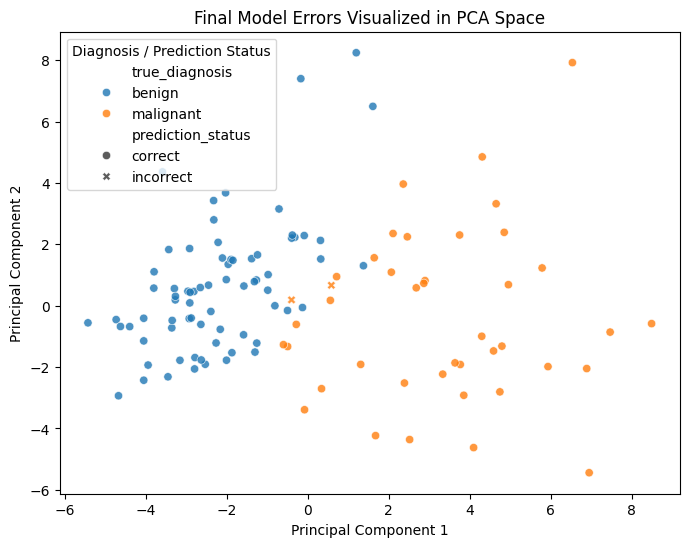

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=test_analysis_df,
    x="PC1",
    y="PC2",
    hue="true_diagnosis",
    style="prediction_status",
    alpha=0.8
)

plt.title("Final Model Errors Visualized in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Diagnosis / Prediction Status")
plt.show()

This plot shows where the final model's errors occur in the PCA space. If the misclassified samples appear near the overlap region between benign and malignant samples, this suggests that the model errors are related to the natural ambiguity already observed in the unsupervised analysis.

In [ ]:
error_cluster_table = pd.crosstab(
    test_analysis_df["prediction_status"],
    test_analysis_df["gmm_cluster"],
    rownames=["Prediction Status"],
    colnames=["GMM Cluster"]
)

display(error_cluster_table)

GMM Cluster,0,1
Prediction Status,,
correct,45,67
incorrect,0,2


The final model made only two errors on the test set. Both errors were false negatives: malignant tumors that were predicted as benign.

This is important in the medical context because false negatives correspond to malignant cases that would not be detected by the model. Therefore, even though the overall performance is strong, these errors are the most critical limitation.

The error analysis shows that both misclassified malignant samples were assigned to GMM Cluster 1. From the previous GMM crosstab, Cluster 1 was the cluster containing mostly benign samples. This means that the misclassified malignant tumors were also considered benign-like by the unsupervised clustering model.

The GMM probabilities support this interpretation. One misclassified sample had probability 0.999987 of belonging to Cluster 1, and the other had probability 0.847995. Therefore, the supervised model errors occurred in regions that the unsupervised model also identified as closer to the benign structure.

This connects the supervised and unsupervised parts of the project: the model errors are not random, but appear to occur in ambiguous regions of the feature space where malignant tumors resemble benign ones.

### Connection Summary

The unsupervised and supervised results support the same general conclusion: the benign/malignant distinction is strongly reflected in the structure of the feature space.

PCA showed that the original 30-dimensional dataset has a lower-dimensional structure, since 7 principal components retained at least 90% of the variance and 10 components retained at least 95%. This motivated the supervised comparison between models trained on the original features and models trained with PCA inside the pipeline.

The supervised results confirmed that PCA preserved most of the predictive information. The PCA-based models performed similarly or slightly better than their original-feature counterparts, and the best model overall was SVM with RBF kernel and PCA.

The clustering results also supported this connection. Both K-Means and GMM discovered clusters that were meaningfully related to the true diagnosis labels. GMM showed especially strong agreement with the diagnosis labels, although adding GMM cluster-membership probabilities as extra supervised features did not clearly improve predictive performance. This suggests that the clustering information was useful for interpretation, but mostly redundant with the original features and PCA representation.

Finally, the error analysis showed that the final model's two mistakes occurred on malignant samples that were assigned to the mostly benign GMM cluster. This suggests that the model errors were not random, but occurred in ambiguous regions of the feature space where malignant tumors resembled benign tumors.

## Reflection and Limitations

This project showed that the Breast Cancer Wisconsin dataset contains a strong relationship between the numerical cell nucleus features and the diagnosis. A key strength of the analysis was that the unsupervised and supervised parts supported each other: the dimensionality reduction and clustering methods revealed structure related to the benign/malignant distinction, while the supervised models showed that this structure can be used for accurate prediction.

What worked best was the use of PCA as both a visualization tool and a feature transformation. PCA reduced the dimensionality of the dataset while preserving most of the relevant diagnostic information. This was important because it suggested that several original features were redundant and that the main structure of the dataset could be represented in fewer dimensions.

The most convincing model was the SVM with RBF kernel using PCA features. Compared with the other models, it provided the strongest overall balance between predictive performance and generalization. The result suggests that the dataset is mostly separable, but that a nonlinear decision boundary can still be useful.

One surprising result was that the clustering methods, despite not using the diagnosis labels during training, produced groups that were strongly related to the true classes. This supports the idea that the benign/malignant distinction is present in the geometry of the feature space. However, clustering was not perfect, especially in the overlapping region between classes, so it should not be used as a replacement for supervised classification.

The main limitation of the study is that the final model still produced a small number of false negatives. In a medical context, this is the most important type of error because it means that a malignant tumor is classified as benign. Future work could therefore focus on adjusting the classification threshold to increase malignant recall, even if this increases the number of false positives.

Another limitation is that the dataset is relatively clean and small compared with real clinical data. The results are strong, but they may not fully represent performance on noisier or more diverse medical datasets. Overall, the project connects hidden structure and prediction: unsupervised methods revealed meaningful patterns, and supervised models showed that these patterns can support accurate diagnosis prediction.

## Reflection and Limitations

This project showed that the Breast Cancer Wisconsin dataset contains a strong relationship between the numerical cell nucleus features and the diagnosis. One of the main strengths of the analysis was that the unsupervised and supervised parts led to consistent conclusions. PCA, t-SNE, K-Means, and GMM all revealed structure related to the benign/malignant distinction, and the supervised models confirmed that this structure can be used for accurate prediction.

What worked best was the combination of PCA and supervised classification. PCA was useful not only for visualization, but also as a lower-dimensional feature representation that preserved most of the relevant diagnostic information. The fact that the PCA-based models performed as well as, or slightly better than, the original-feature models suggests that many original variables contain redundant information.

The most convincing model was the SVM with RBF kernel using PCA features. It achieved the strongest cross-validation result and also performed very well on the untouched test set. This suggests that a slightly nonlinear decision boundary can improve performance, although the small differences between models show that the dataset is already highly separable.

One surprising result was that unsupervised clustering, despite not using the diagnosis labels during training, produced clusters that were strongly related to the true medical classes. However, clustering was not perfect, especially in the overlapping region of the PCA space. This shows that hidden structure exists in the data, but also that supervised learning is more appropriate when the goal is reliable diagnosis prediction.

The main limitation of the study is that the final model still produced a small number of false negatives. In a medical context, this is the most important type of error because it means that a malignant tumor is classified as benign. Therefore, future work could focus on adjusting the classification threshold to increase malignant recall, even if this produces more false positives. Another limitation is that this dataset is relatively clean and small, so the results may not fully represent performance on noisier real-world clinical data.

Overall, the project connects hidden structure and prediction: the unsupervised methods revealed meaningful patterns in the data, and the supervised models showed that these patterns can support accurate classification. The strongest conclusion is not only that the model performs well, but that the geometry of the data itself is closely related to the medical diagnosis.